# Chapter 5 — Gaussian wave packet

Units $\hbar=m=1$. We check $\sigma_x\sigma_p=\hbar/2$ with a Fourier transform, then free spreading $\sigma(t)=\sigma_0\sqrt{1+(\hbar t/2m\sigma_0^2)^2}$.

*PHY321 Notebook — works offline: numpy and matplotlib are enough.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(321)  # fixed seed: reproducible results

In [2]:
N, L = 4096, 160.0
x = (np.arange(N) - N//2) * (L/N); dx = L/N
k = 2*np.pi*np.fft.fftfreq(N, d=dx)
s0 = 1.0
psi = (2*np.pi*s0**2)**-0.25 * np.exp(-x**2/(4*s0**2)).astype(complex)   # |ψ|² Gaussian with standard deviation σ0
def width(f, grid): 
    p = np.abs(f)**2; p = p/p.sum(); m = (grid*p).sum(); return np.sqrt(((grid-m)**2*p).sum())
phi = np.fft.fft(psi)
print("σx =", width(psi, x), "  σp =", width(phi, k), "  σxσp =", width(psi, x)*width(phi, k), "(expected 0.5)")

σx = 0.9999999999999999   σp = 0.49999999999999994   σxσp = 0.4999999999999999 (expected 0.5)


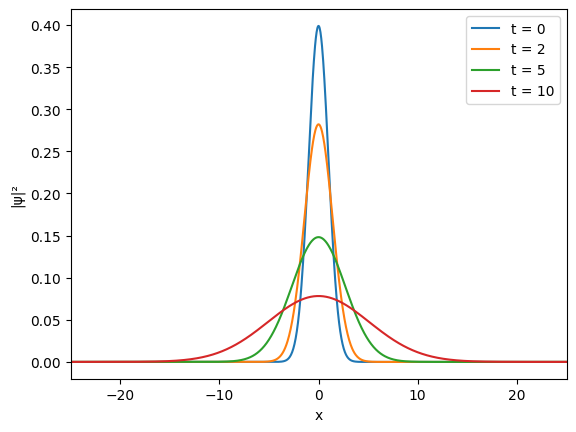

t =   0   σ(num) = 1.0000   σ(th) = 1.0000
t =   2   σ(num) = 1.4142   σ(th) = 1.4142
t =   5   σ(num) = 2.6926   σ(th) = 2.6926
t =  10   σ(num) = 5.0990   σ(th) = 5.0990


In [3]:
def evolve(t): return np.fft.ifft(np.fft.fft(psi) * np.exp(-1j*k**2*t/2))
ts = [0, 2, 5, 10]
for t_ in ts:
    plt.plot(x, np.abs(evolve(t_))**2, label=f"t = {t_}")
plt.xlim(-25, 25); plt.xlabel('x'); plt.ylabel('|ψ|²'); plt.legend(); plt.show()
for t_ in ts:
    th = s0*np.sqrt(1 + (t_/(2*s0**2))**2)
    print(f"t = {t_:>3}   σ(num) = {width(evolve(t_), x):.4f}   σ(th) = {th:.4f}")

Momentum does not change: $\sigma_p$ stays $1/(2\sigma_0)$; it is the relative phase between components that spreads the packet.

In [4]:
print("σp(t=10) =", width(np.fft.fft(evolve(10)), k), "  1/(2σ0) =", 1/(2*s0))

σp(t=10) = 0.49999999999999994   1/(2σ0) = 0.5
